# 21 - Custom Workflows: Your Own Reusable Interpretation Recipe

**Part B - Petrophys Curriculum**

`pp.interpret` looks at a well and chooses its methods for you. Often you need the
opposite: a recipe that *you* choose (these endpoints, this porosity route, this Rw,
these cutoffs), applied the same way to every well, checked before it runs, and saved
so a colleague can run it too. That is a **custom workflow**: a `pp.Workflow` built
from the library's tested calculation steps and from your own functions.

This lesson builds a clastic recipe for 30/6-5 and a carbonate recipe for the COSTA
Kharaib-2 wells, adds steps of your own, wraps the automatic `pp.interpret` inside a
recipe, saves and reloads the recipes, and runs one across the field.

## Learning goals

- Build a `pp.Workflow` from `petrophys.workflow.steps` and read its `describe()` table.
- Check a workflow against a well with `check()`, and understand strict and
  non-strict runs.
- Read a run's trace, window summary, formation table, plot and exports.
- Write your own step with `@pp.workflow_step`, and put `pp.interpret` inside a
  recipe with `steps.interpret()`.
- Save, reload and share a workflow, and change a parameter for one run with `params=`.
- Run one workflow over many wells with `run_many` and compare them in a table and a figure.

### Prerequisites

Lesson 10 (the prebuilt dynamic workflow and its trace) and the Part A calculation
lessons (clay volume, porosity, Rw, saturation, net pay). Lesson 18 introduces the
COSTA field used in sections 7 and 8.

## Why this matters

A field study is only comparable if every well is interpreted with the same recipe,
and a recipe is only reviewable if it is written down. With `pp.interpret` the methods
can differ from well to well, because it adapts to the data. A custom workflow fixes
the methods and parameters, refuses to run when an input is missing instead of quietly
doing something else, records every decision, and travels as a small JSON file. It is
the difference between "I ran the interpretation" and "here is exactly what was run".

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import json
import pathlib
import tempfile
import warnings

import lasio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import petrophys as pp
from petrophys.workflow import WorkflowValidationError, steps

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)
print("petrophys", pp.__version__)

petrophys 3.0.0


## 1. A clastic recipe for 30/6-5

We start from the flagship North Sea well and its bundled formation tops. Whenever
this well's curves are standardized (for a plot, or inside `pp.interpret`), Petrophys
prints a `UserWarning` for `SWC` and one for `SOC`: the core saturation curves are
stored in percent although the header labels them `frac`, so they are divided by 100.
It is a genuine note about this file, not about the lesson, and it would repeat in
every run below, so we hide **only that message** up front.

In [2]:
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
print(well.name, "|", well.top, "-", well.bottom, well.depth_unit, "|", well.n_curves, "curves")

# Hide only the SWC/SOC percent note explained above; other warnings still show.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

30/6-5 | 176.60999 - 3556.08032 m | 20 curves


Each step comes from `petrophys.workflow.steps` and wraps a tested library
calculation; the steps choose no methods on their own. Our choices, all visible in the
recipe:

| Step | Choice | Why |
|---|---|---|
| `temperature()` | Linear profile from the header BHT | Rw is corrected to formation temperature |
| `clay_volume` | Gamma ray, 20 and 110 API endpoints | Clean sand and shale read off the GR log |
| `porosity` | Neutron-density, sandstone matrix | The standard clastic route |
| `formation_water` | Rw 0.07 ohm.m measured at 230 degF | The documented Rw for this well |
| `saturation` | Archie, a = 1, m = 2, n = 2 | A simple, transparent starting point |
| `permeability` | Timur with Swirr 0.15 | An explicit Swirr instead of a log estimate |
| `net_pay` | VCL < 0.35, PHIE > 0.10, SW < 0.60 | Project cutoffs |

In [3]:
clastic = pp.Workflow("30/6-5 clastic quick look", [
    steps.temperature(),
    steps.clay_volume(method="gr", gr_clean=20, gr_shale=110),
    steps.porosity(method="neutron_density", matrix="sandstone"),
    steps.formation_water(rw=0.07, rw_temp_f=230),
    steps.saturation(model="archie", a=1, m=2, n=2),
    steps.permeability(method="timur", swirr=0.15),
    steps.net_pay(vcl_cutoff=0.35, phie_cutoff=0.10, sw_cutoff=0.60),
])
clastic.describe()

,Step,Kind,Requires,Produces,Parameters
1,temperature,temperature,-,TEMP,defaults
2,clay_volume,clay_volume,GR,VCL,"method='gr', gr_clean=20, gr_shale=110"
3,porosity,porosity,"NPHI, RHOB, VCL","PHID, PHIN, PHIT, PHIE","method='neutron_density', matrix='sandstone'"
4,formation_water,formation_water,-,RW,"rw=0.07, rw_temp_f=230"
5,saturation,saturation,"PHIE, RDEP or RT, RW","SW, SXO","model='archie', a=1, m=2, n=2"
6,permeability,permeability,PHIE,PERM,"method='timur', swirr=0.15"
7,net_pay,net_pay,"VCL, PHIE, SW","NET_ROCK, NET_RES, NET_PAY","vcl_cutoff=0.35, phie_cutoff=0.1, sw_cutoff=0.6"


`describe()` is the recipe at a glance: what each step needs, what it adds, and the
parameters you set (everything else is a documented default). Parameters are validated
when a step is created, so mistakes surface immediately, with the closest valid option:

In [4]:
for attempt in (lambda: steps.porosity(method="densty"),
                lambda: steps.net_pay(vcl=0.35),
                lambda: steps.formation_water(rw=0.07)):
    try:
        attempt()
    except (TypeError, ValueError) as error:
        print(f"{type(error).__name__}: {error}\n")

ValueError: Invalid steps.porosity() parameters:
  - method='densty' is not valid; use one of: density, neutron_density, neutron, sonic (did you mean 'density'?)

TypeError: steps.net_pay() got unexpected parameter(s) 'vcl' (did you mean 'vcl_cutoff'?). Parameters: vcl_cutoff, phie_cutoff, sw_cutoff, lithology, vcl_curve, phie_curve, sw_curve.

ValueError: Invalid steps.formation_water() parameters:
  - rw_temp_f is required with rw: the temperature (degF) at which rw was measured, e.g. rw=0.07, rw_temp_f=230



## 2. Check before you run

`check()` walks the steps in order and reports, for every input, where it will come
from: the well itself or an earlier step.

In [5]:
clastic.check(well)

,Step,Requires,Met,Source,Note
0,temperature,(nothing),True,,
1,clay_volume,GR,True,well (GR),
2,porosity,NPHI,True,well (NPHI),
3,porosity,RHOB,True,well (RHOB),
4,porosity,VCL,True,step clay_volume,
5,formation_water,(nothing),True,,
6,saturation,PHIE,True,step porosity,
7,saturation,RDEP or RT,True,well (RDEP),
8,saturation,RW,True,step formation_water,
9,permeability,PHIE,True,step porosity,


Now break the recipe on purpose by dropping the clay-volume step. `check` shows the
missing input *and* its consequences further down. A normal (strict) run stops before
calculating anything and lists every problem at once.

In [6]:
draft = clastic.copy("draft without clay volume").remove("clay_volume")
report = draft.check(well)
print(report.loc[~report["Met"], ["Step", "Requires", "Note"]].to_string(index=False))
print()
try:
    draft.run(well)
except WorkflowValidationError as error:
    print(error)

        Step Requires                                                                                          Note
    porosity      VCL needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'porosity'
  saturation     PHIE           needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
permeability     PHIE           needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
     net_pay      VCL  needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'net_pay'
     net_pay     PHIE           needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
     net_pay       SW             needs SW (water saturation), which step 'saturation' would produce but cannot run

Workflow 'draft without clay volume' cannot run on well '30/6-5':
  - porosity: needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'porosity'
  - saturatio

With `strict=False` the run goes ahead, skips what cannot run, and says why. It is
useful for exploring, but always read `steps_skipped`: a skipped step is missing work,
not a zero.

In [7]:
partial = draft.run(well, strict=False)
print("status:", partial.status)
for name, reason in partial.steps_skipped.items():
    print(f"  {name}: {reason}")

status: partial
  porosity: Needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'porosity'
  saturation: Needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
  permeability: Needs PHIE (effective porosity), which step 'porosity' would produce but cannot run
  net_pay: Needs VCL (clay volume), which is not on this well; add steps.clay_volume() before 'net_pay'; needs PHIE (effective porosity), which step 'porosity' would produce but cannot run; needs SW (water saturation), which step 'saturation' would produce but cannot run


Order is part of the recipe. A step can only use curves from the well or from
*earlier* steps, so adding a step whose output an earlier step needed is refused at once:

In [8]:
try:
    pp.Workflow("wrong order", [steps.saturation()]).add(
        steps.formation_water(rw=0.07, rw_temp_f=230))
except WorkflowValidationError as error:
    print(error)

Steps run in order, so these inputs would never be available:
  - 'saturation' needs RW, which only the later step 'formation_water' produces; move 'formation_water' before 'saturation' (wf.insert(step, before='saturation'))


## 3. Run it and read the result

`run()` works on a copy of the well: `run.well` is the interpreted copy and `well`
is untouched. The trace records each step's method, inputs, outputs and decisions,
including values the step picked itself.

In [9]:
run = clastic.run(well)
run.print_trace()

WORKFLOW TRACE: 30/6-5 clastic quick look on 30/6-5
Status: complete | Run: 7 | Skipped: 0 | Warnings: 0
[OK  ] temperature  (linear_gradient_from_BHT)
       Outputs: TEMP
       -> Anchored to BHT 258.8 degF at 11667 ft
       -> Gradient 1.635 degF/100 ft (29.8 degC/km); TEMP 77.5-258.8 degF
[OK  ] clay_volume  (gr_linear)
       Inputs:  GR
       Outputs: VCL
       -> GR clean = 20.0 API (given), GR shale = 110.0 API (given); linear transform
[OK  ] porosity  (neutron_density)
       Inputs:  RHOB, NPHI, VCL
       Outputs: PHID, PHIN, PHIT, PHIE
       -> PHID = (2.65 - RHOB) / (2.65 - 1)
       -> PHIN = NPHI + 0.02, limited to 0-0.6
       -> PHIT = adaptive neutron-density combination (density alone in gas crossover)
       -> PHIE = PHIT - VCL * 0.15
[OK  ] formation_water  (given_rw_arps)
       Inputs:  TEMP
       Outputs: RW
       -> Corrected along the TEMP curve
       -> Rw 0.07 ohm.m at 230 degF (given), corrected with Arps' equation
       -> RW 0.0624-0.1967 ohm.m

On 30/6-5 a whole-well total would include shallow overburden that happens to pass
the cutoffs, so we summarize the Brent reservoir window (2841-2958 m). `pp.interpret`
is shown alongside. The numbers differ because the recipes differ: `pp.interpret`
picks its own clay endpoints, a matrix per lithology and a saturation model per
sample. That is exactly why writing the recipe down matters.

In [10]:
auto = pp.interpret(well, rw=0.07, rw_meas_temp_f=230)
rows = {}
for label, result in (("custom recipe", run), ("pp.interpret", auto)):
    brent = result.summary(top=2841, bottom=2958)
    rows[label] = {
        "Brent net pay (m)": brent["net_thickness"]["net_pay"],
        "mean PHIE": brent["key_results"]["PHIE"]["mean"],
        "mean SW": brent["key_results"]["SW"]["mean"],
        "mean VCL": brent["key_results"]["VCL"]["mean"],
    }
pd.DataFrame(rows).round(3)

,custom recipe,pp.interpret
Brent net pay (m),20.720,35.500
mean PHIE,0.132,0.171
mean SW,0.826,0.645
mean VCL,0.443,0.140


In [11]:
table = run.formation_summary(rank="formation").set_index("Formation")
table.loc[["Ness Fm.", "Etive Fm."],
          ["Gross (m)", "Net Pay (m)", "NTG", "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]].round(3)

,Gross (m),Net Pay (m),NTG,Avg PHIE,Avg Sw,Avg Perm (mD)
Formation,,,,,,
Ness Fm.,24.079,0.305,0.013,0.196,0.579,295.139
Etive Fm.,92.964,20.422,0.220,0.214,0.280,420.245


The interpreted copy plots like any other well:

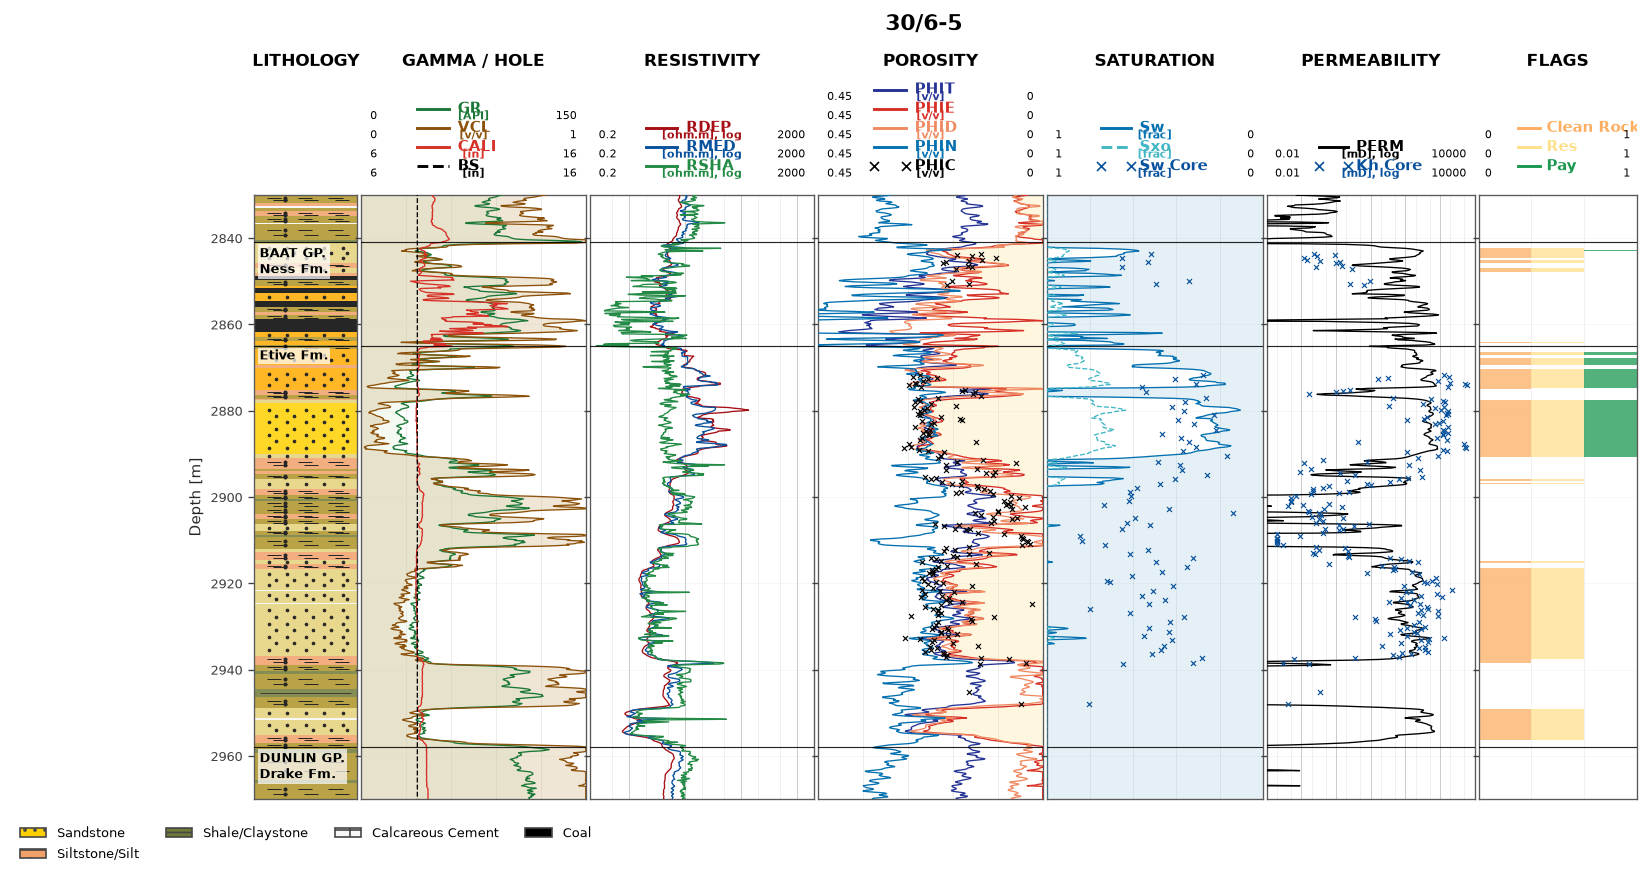

In [12]:
viewer = pp.plot(run.well, depth_range=(2830, 2970), figsize=(12, 7),
                 tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "POROSITY",
                         "SATURATION", "PERMEABILITY", "FLAGS"])
viewer.show()
viewer.close()

## 4. Your own step: an apparent-Rw check

Any function can become a step. It takes the well first and its parameters as
keywords, and returns its curves as a `{name: array}` dict with one value per depth
sample. `requires` and `produces` declare the inputs and the outputs with their
units, so `check()` and the trace treat it like a built-in step.

Our step computes the apparent water resistivity, Rwa = Rt x PHIE^m / a. In clean,
water-bearing sand Rwa should scatter around the true Rw, so it is a classic check on
the Rw we assumed.

In [13]:
@pp.workflow_step(requires=["RDEP", "PHIE"], produces={"RWA": "ohm.m"})
def apparent_rw(well, a=1.0, m=2.0):
    """Apparent water resistivity, Rwa = RT * PHIE^m / a."""
    rt = well.get("RDEP").data
    phie = np.clip(well.get("PHIE").data, 0.0, None)
    return {"RWA": rt * phie**m / a}

checked = clastic.copy("30/6-5 quick look + Rwa").add(apparent_rw())
run = checked.run(well)
last = run.steps[-1]
print(last.method, "| inputs", last.input_curves, "| outputs", last.output_curves,
      "|", run.well.get("RWA").unit)

__main__.apparent_rw | inputs ['RDEP', 'PHIE'] | outputs ['RWA'] | ohm.m


In this recipe the lower Etive (about 2895-2955 m) is water-bearing. Compare Rwa there
with the Rw curve the workflow used:

178 clean water-leg samples
Rwa P10 / P50: 0.040 / 0.054 ohm.m
Rw used (median): 0.071 ohm.m


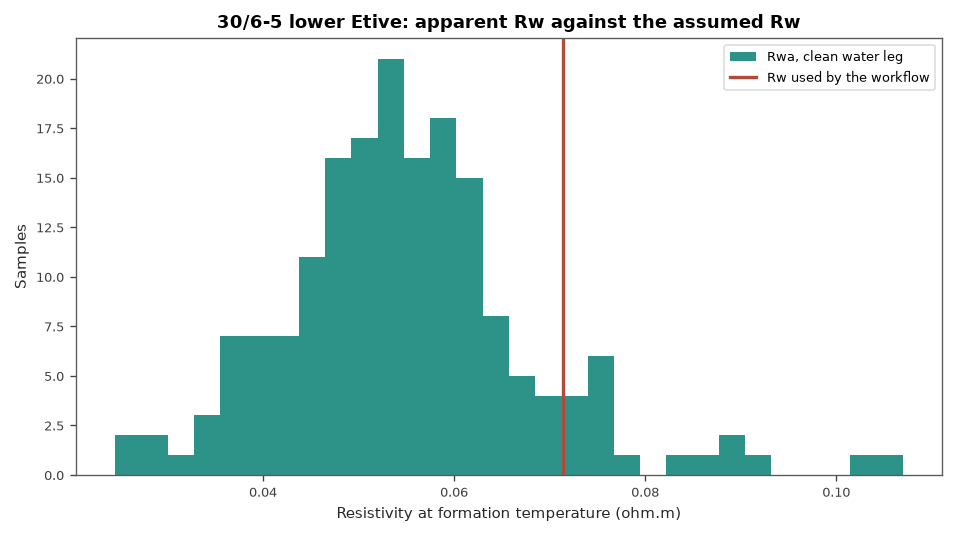

In [14]:
depth = run.well.depth
wet_sand = ((depth >= 2895) & (depth <= 2955)
            & (run.well.get("VCL").data < 0.3) & (run.well.get("PHIE").data > 0.10))
rwa = run.well.get("RWA").data[wet_sand]
rw_used = np.nanmedian(run.well.get("RW").data[wet_sand])
print(f"{wet_sand.sum()} clean water-leg samples")
print(f"Rwa P10 / P50: {np.nanpercentile(rwa, 10):.3f} / {np.nanpercentile(rwa, 50):.3f} ohm.m")
print(f"Rw used (median): {rw_used:.3f} ohm.m")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(rwa[np.isfinite(rwa)], bins=30, color="#087f73", alpha=0.85, label="Rwa, clean water leg")
ax.axvline(rw_used, color="#b24a3a", lw=2, label="Rw used by the workflow")
ax.set_xlabel("Resistivity at formation temperature (ohm.m)")
ax.set_ylabel("Samples")
ax.set_title("30/6-5 lower Etive: apparent Rw against the assumed Rw")
ax.legend()
plt.tight_layout()
plt.show()

If Rwa sits clearly *below* the assumed Rw in a zone you believe is wet, either Rw is
too high or porosity (or m) is off; if it sits *above*, the zone may hold hydrocarbon.
The step does not decide for you, but it puts the evidence next to the recipe, and it
reruns on every well the recipe touches. Exercise 1 follows this up.

## 5. Put `pp.interpret` inside a recipe

`steps.interpret(**settings)` runs the complete prebuilt workflow as one step. The
settings are the usual `pp.interpret` settings, validated when the step is created.
Your own steps can follow it (or precede it), and `steps.formation_summary()` computes
the per-formation table as part of the run.

In [15]:
extended = pp.Workflow("pp.interpret + Rwa check", [
    steps.interpret(rw=0.07, rw_meas_temp_f=230),
    apparent_rw(),
    steps.formation_summary(rank="formation"),
])
extended_run = extended.run(well)
print(extended_run)
print("Same SW as pp.interpret:",
      np.allclose(extended_run.well.get("SW").data, auto.well.get("SW").data, equal_nan=True))
print("Artifacts:", {name: type(value).__name__ for name, value in extended_run.artifacts.items()})

<WorkflowRunResult 'pp.interpret + Rwa check' on '30/6-5': complete, 3 run, 0 skipped>
Same SW as pp.interpret: True
Artifacts: {'interpret': 'DynamicWorkflowResult', 'formation_summary': 'DataFrame'}


The step's trace condenses the automatic routing to one line per sub-step, and the
full `DynamicWorkflowResult` stays available in `run.artifacts["interpret"]`:

In [16]:
for decision in extended_run.steps[0].decisions[:8]:
    print(" ", decision)
table = extended_run.artifacts["formation_summary"].set_index("Formation")
table.loc[["Ness Fm.", "Etive Fm."], ["Net Pay (m)", "Avg PHIE", "Avg Sw"]].round(3)

  normalization: curve_alias_and_unit_standardization
  input_context: validated_geology_selection
  temperature: linear_gradient_from_BHT
  bad_hole: caliper_drho_flags
  vclay: linear
  rcl: lithology_shale_median_rt
  rmf: las_metadata_assumed_reference_temperature
  porosity: component_based


,Net Pay (m),Avg PHIE,Avg Sw
Formation,,,
Ness Fm.,4.572,0.189,0.672
Etive Fm.,30.937,0.220,0.321


## 6. Save, reload, share and vary

A workflow saves as a small JSON file: the step types, names and the parameters you
set. Loading re-creates every step through its factory, so everything is validated
again. We write into a temporary folder and print file names only.

In [17]:
folder = pathlib.Path(tempfile.mkdtemp())
path = clastic.save(folder / "30_6-5_clastic.json")
saved = json.loads(path.read_text())
print(path.name, "|", {key: saved[key] for key in ("schema", "schema_version", "name")})
for step in saved["steps"]:
    print(" ", step)

30_6-5_clastic.json | {'schema': 'petrophys.workflow', 'schema_version': 1, 'name': '30/6-5 clastic quick look'}
  {'name': 'temperature', 'kind': 'temperature', 'params': {}}
  {'name': 'clay_volume', 'kind': 'clay_volume', 'params': {'method': 'gr', 'gr_clean': 20, 'gr_shale': 110}}
  {'name': 'porosity', 'kind': 'porosity', 'params': {'method': 'neutron_density', 'matrix': 'sandstone'}}
  {'name': 'formation_water', 'kind': 'formation_water', 'params': {'rw': 0.07, 'rw_temp_f': 230}}
  {'name': 'saturation', 'kind': 'saturation', 'params': {'model': 'archie', 'a': 1, 'm': 2, 'n': 2}}
  {'name': 'permeability', 'kind': 'permeability', 'params': {'method': 'timur', 'swirr': 0.15}}
  {'name': 'net_pay', 'kind': 'net_pay', 'params': {'vcl_cutoff': 0.35, 'phie_cutoff': 0.1, 'sw_cutoff': 0.6}}


In [18]:
reloaded = pp.Workflow.load(path)
print("Identical recipe: ", reloaded == clastic)
print("Identical results:", np.allclose(reloaded.run(well).well.get("SW").data,
                                        clastic.run(well).well.get("SW").data, equal_nan=True))

Identical recipe:  True
Identical results: True


Custom steps are saved by import path (`module:function`). `apparent_rw` lives in this
notebook (`__main__`), so saving a recipe that uses it warns that the file only loads
where that function is defined. To share such a recipe, put the step in a module.

In [19]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    checked.save(folder / "30_6-5_with_rwa.json")
for warning in caught:
    print("Warning:", warning.message)

Results travel with their recipe: `to_las` writes the workflow into the LAS `~Params`
section (one `PP_STEPnn` entry per step, the full JSON in `~Other`), and `to_json`
writes the complete trace.

In [20]:
las = lasio.read(run.to_las(folder / "30_6-5_quicklook.las"))
for item in las.params:
    if item.mnemonic.startswith("PP_"):
        print(f"{item.mnemonic:<11} {item.value:<16} {item.descr}")
trace = json.loads(run.to_json())
print("\nJSON trace:", trace["schema"], "|", len(trace["steps"]), "steps |", trace["status"])

PP_VERSION  3.0.0            petrophys version
PP_WORKFLOW 30/6-5 quick look + Rwa Custom workflow
PP_STATUS   complete         Workflow status
PP_STEP01   temperature      steps.temperature() [run]
PP_STEP02   clay_volume      steps.clay_volume(method='gr', gr_clean=20, gr_shale=110) [run]
PP_STEP03   porosity         steps.porosity(method='neutron_density', matrix='sandstone') [run]
PP_STEP04   formation_water  steps.formation_water(rw=0.07, rw_temp_f=230) [run]
PP_STEP05   saturation       steps.saturation(model='archie', a=1, m=2, n=2) [run]
PP_STEP06   permeability     steps.permeability(method='timur', swirr=0.15) [run]
PP_STEP07   net_pay          steps.net_pay(vcl_cutoff=0.35, phie_cutoff=0.1, sw_cutoff=0.6) [run]
PP_STEP08   apparent_rw      apparent_rw() [run]

JSON trace: custom_workflow_trace | 8 steps | complete


`params=` changes a step for one run without editing the workflow, which makes a
sensitivity check one line each:

In [21]:
for n in (1.8, 2.0, 2.2):
    trial = clastic.run(well, params={"saturation": {"n": n}})
    net_pay = trial.summary(top=2841, bottom=2958)["net_thickness"]["net_pay"]
    print(f"n = {n}: Brent net pay {net_pay:.1f} m")
print("The recipe itself is unchanged:", clastic["saturation"])

n = 1.8: Brent net pay 21.2 m
n = 2.0: Brent net pay 20.7 m
n = 2.2: Brent net pay 20.1 m
The recipe itself is unchanged: steps.saturation(model='archie', a=1, m=2, n=2)


## 7. A carbonate recipe for the COSTA Kharaib-2 wells

Each COSTA LAS file covers only the Kharaib-2 reservoir interval, in feet. The
carbonate recipe differs from the clastic one in four deliberate ways:

- **Limestone matrix** for porosity.
- **Field-wide GR endpoints** (10 and 80 API). The Kharaib-2 is mostly clean
  carbonate: per-well P5/P95 endpoints would call each well's dirtiest rock "shale"
  and inflate clay volume.
- **Rw from each well's header.** `rw="header"` reads `RW` and the temperature it was
  measured at (`RWT`) from every file, so one recipe honours each well's water.
- **The COSTA project cutoffs** used in lesson 18: VCL 0.30, PHIE 0.10, SW 0.60.

The files also carry the vendor's interpretation (`PHIE_CC`, `SW_INPUT`). A small
custom step compares our result with it, so the QC is part of the recipe.

In [22]:
@pp.workflow_step(requires=["PHIE", "SW", "PHIE_CC", "SW_INPUT"],
                  produces={"DPHIE": "v/v", "DSW": "v/v"})
def vendor_difference(well):
    """Our PHIE and SW minus the vendor's PHIE_CC and SW_INPUT."""
    return {"DPHIE": well.get("PHIE").data - well.get("PHIE_CC").data,
            "DSW": well.get("SW").data - well.get("SW_INPUT").data}

carbonate = pp.Workflow("Kharaib-2 carbonate screen", [
    steps.temperature(),
    steps.clay_volume(method="gr", gr_clean=10, gr_shale=80),
    steps.porosity(method="neutron_density", matrix="limestone"),
    steps.formation_water(rw="header"),
    steps.saturation(model="archie", a=1, m=2, n=2),
    steps.net_pay(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60, lithology="carbonate"),
    vendor_difference(),
])
carbonate.describe()

,Step,Kind,Requires,Produces,Parameters
1,temperature,temperature,-,TEMP,defaults
2,clay_volume,clay_volume,GR,VCL,"method='gr', gr_clean=10, gr_shale=80"
3,porosity,porosity,"NPHI, RHOB, VCL","PHID, PHIN, PHIT, PHIE","method='neutron_density', matrix='limestone'"
4,formation_water,formation_water,header RW and RWT,RW,rw='header'
5,saturation,saturation,"PHIE, RDEP or RT, RW","SW, SXO","model='archie', a=1, m=2, n=2"
6,net_pay,net_pay,"VCL, PHIE, SW","NET_ROCK, NET_RES, NET_PAY","vcl_cutoff=0.3, phie_cutoff=0.1, sw_cutoff=0.6, lithology='carbonate'"
7,vendor_difference,custom: vendor_difference,"PHIE, SW, PHIE_CC, SW_INPUT","DPHIE, DSW",defaults


In [23]:
hw3 = pp.read(pp.sample("HW-3"), formations=pp.sample("formations_costa"))
hw3_run = carbonate.run(hw3)
print(hw3_run.to_dataframe()[["Step", "Method", "Output Curves"]].to_string(index=False))
print("\nRw:", hw3_run.steps[3].decisions[1])

             Step                     Method              Output Curves
      temperature   linear_gradient_from_BHT                       TEMP
      clay_volume                  gr_linear                        VCL
         porosity            neutron_density     PHID, PHIN, PHIT, PHIE
  formation_water             header_rw_arps                         RW
       saturation                     archie                    SW, SXO
          net_pay                    cutoffs NET_ROCK, NET_RES, NET_PAY
vendor_difference __main__.vendor_difference                 DPHIE, DSW

Rw: Rw 0.0682 ohm.m at 68 degF (LAS header RW and RWT), corrected with Arps' equation


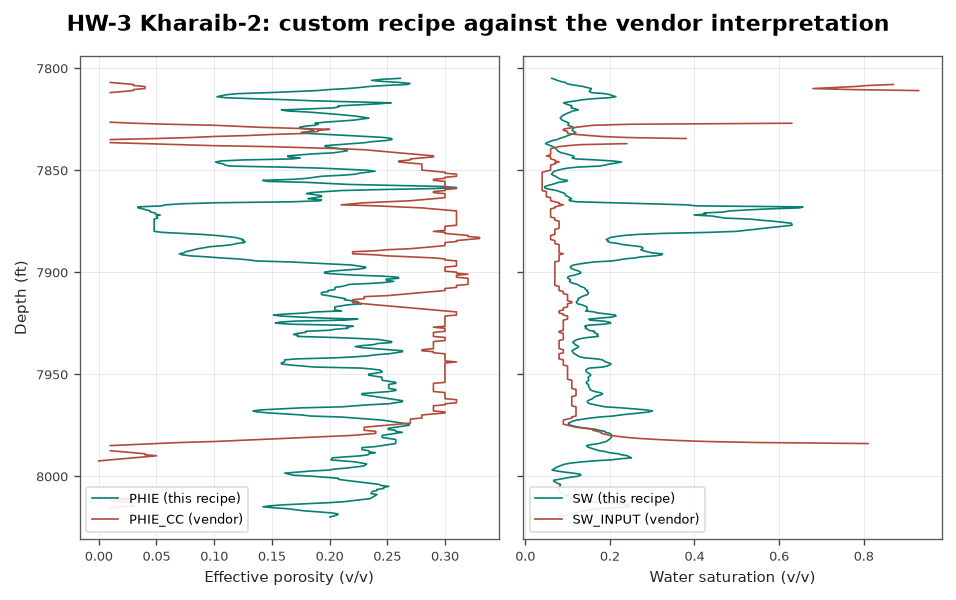

Mean PHIE - PHIE_CC: -0.054
Mean SW - SW_INPUT:  +0.062


In [24]:
data = hw3_run.well
pairs = [("PHIE", "PHIE_CC", "Effective porosity (v/v)"),
         ("SW", "SW_INPUT", "Water saturation (v/v)")]
fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
for ax, (ours, vendor, label) in zip(axes, pairs):
    ax.plot(data.get(ours).data, data.depth, color="#087f73", lw=1, label=f"{ours} (this recipe)")
    ax.plot(data.get(vendor).data, data.depth, color="#b24a3a", lw=1, label=f"{vendor} (vendor)")
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("Depth (ft)")
axes[0].invert_yaxis()
fig.suptitle("HW-3 Kharaib-2: custom recipe against the vendor interpretation")
plt.tight_layout()
plt.show()
print(f"Mean PHIE - PHIE_CC: {np.nanmean(data.get('DPHIE').data):+.3f}")
print(f"Mean SW - SW_INPUT:  {np.nanmean(data.get('DSW').data):+.3f}")

## 8. Run the field with `run_many`

`run_many` takes a list of wells or files, or a folder, attaches the same formation
tops to every well, and keeps going when a well fails: each failure is recorded with
its reason.

In [25]:
costa = pp.list_samples("costa")
wells = [pp.sample(name) for name in costa]
batch = carbonate.run_many(wells, formations=pp.sample("formations_costa"))
print(batch)
for name, message in batch.errors.items():
    print(f"{name}: {message}")

<WorkflowBatchResult 'Kharaib-2 carbonate screen': 16 wells run, 1 errors>
HW-31: WorkflowValidationError: Workflow 'Kharaib-2 carbonate screen' cannot run on well 'HW-31':
  - vendor_difference: needs SW_INPUT, which has no valid samples on this well
Run wf.check(well) for the full table, or pass strict=False to skip these steps and run the rest.


HW-31's file has a `SW_INPUT` curve with no valid values, so the comparison step
cannot run there and the strict run refuses the whole well. With `strict=False` the
well runs every other step and skips only the comparison:

In [26]:
batch = carbonate.run_many(wells, formations=pp.sample("formations_costa"), strict=False)
field = batch.summary_table()
field[["Well", "Status", "Skipped Steps", "Gross", "Net Pay", "NTG", "Avg PHIE", "Avg Sw"]].round(3)

,Well,Status,Skipped Steps,Gross,Net Pay,NTG,Avg PHIE,Avg Sw
0,HW-10,complete,,190.5,11.0,0.058,0.243,0.515
1,HW-24,complete,,216.5,147.0,0.679,0.240,0.270
2,HW-25,complete,,206.5,151.5,0.734,0.254,0.101
3,HW-26,complete,,172.5,34.5,0.200,0.147,0.429
4,HW-27,complete,,204.5,0.0,0.000,NaN,NaN
5,HW-28,complete,,203.5,4.5,0.022,0.137,0.537
6,HW-29,complete,,222.5,188.0,0.845,0.281,0.106
7,HW-3,complete,,215.5,194.5,0.903,0.207,0.137
8,HW-30,complete,,240.5,209.5,0.871,0.303,0.148
9,HW-31,partial,vendor_difference,210.5,0.0,0.000,NaN,NaN


`summary_table()` gives one row per well: status, the steps run and skipped, and net
pay with pay-averaged properties over the logged interval (or a `top`/`bottom` window;
`by_formation=True` gives one row per formation). The figure ranks the wells and checks
the recipe against the vendor across the field:

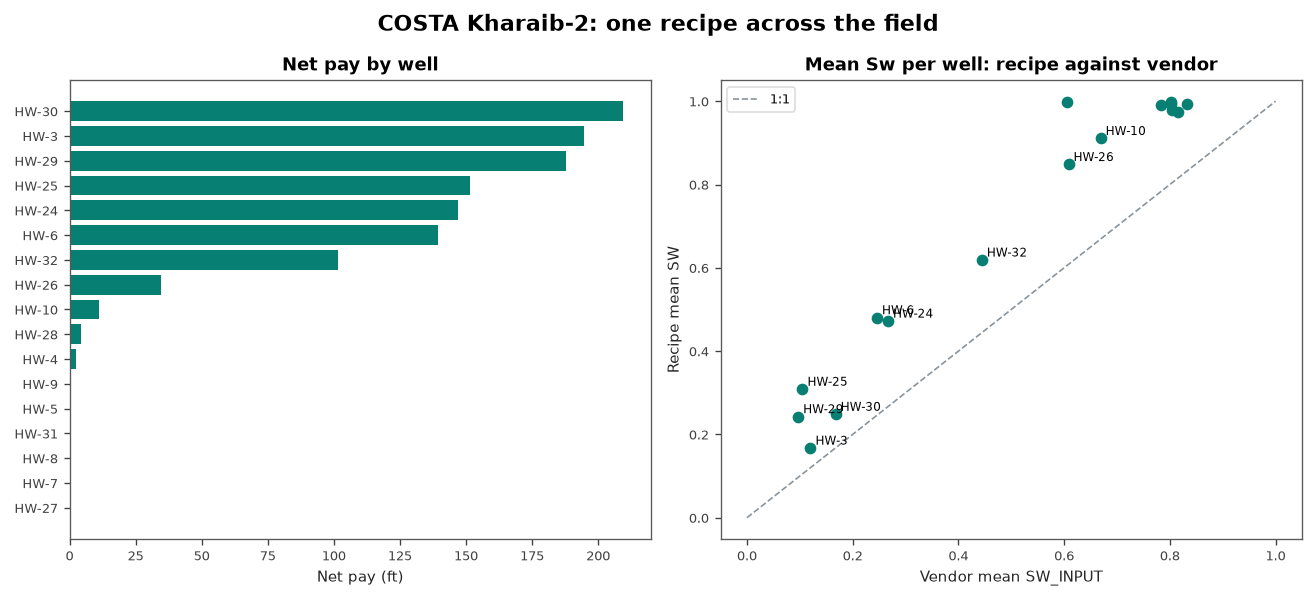

In [27]:
recipe_sw = {name: np.nanmean(result.well.get("SW").data) for name, result in batch.results.items()}
vendor_sw = {name: np.nanmean(result.well.get("SW_INPUT").data)
             for name, result in batch.results.items()
             if np.isfinite(result.well.get("SW_INPUT").data).any()}
ranked = field.sort_values("Net Pay")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 5))
left.barh(ranked["Well"], ranked["Net Pay"], color="#087f73")
left.set_xlabel("Net pay (ft)")
left.set_title("Net pay by well")
names = list(vendor_sw)
right.scatter([vendor_sw[n] for n in names], [recipe_sw[n] for n in names], color="#087f73")
for n in names:
    if recipe_sw[n] < 0.95:  # the wells piled up near Sw = 1 are left unlabelled
        right.annotate(n, (vendor_sw[n], recipe_sw[n]), fontsize=7, xytext=(3, 2),
                       textcoords="offset points")
right.plot([0, 1], [0, 1], color="#8a949c", ls="--", lw=1, label="1:1")
right.set_xlabel("Vendor mean SW_INPUT")
right.set_ylabel("Recipe mean SW")
right.set_title("Mean Sw per well: recipe against vendor")
right.legend()
fig.suptitle("COSTA Kharaib-2: one recipe across the field")
plt.tight_layout()
plt.show()

Points above the 1:1 line are wells where the recipe reads wetter than the vendor. An
offset shared by most wells points to a recipe-wide choice (Rw, m, n or the porosity
route) rather than to one well, and is worth resolving before trusting the ranking:
the recipe makes that choice explicit and easy to change.

The same recipe answers "what if" questions across the field: here the total net pay
for three Sw cutoffs, each a one-line `params` change.

In [28]:
for cutoff in (0.5, 0.6, 0.7):
    trial = carbonate.run_many(wells, strict=False, params={"net_pay": {"sw_cutoff": cutoff}})
    print(f"SW cutoff {cutoff:.1f}: field net pay {trial.summary_table()['Net Pay'].sum():,.1f} ft")

SW cutoff 0.5: field net pay 1,128.5 ft


SW cutoff 0.6: field net pay 1,184.0 ft


SW cutoff 0.7: field net pay 1,242.5 ft


## Pitfalls & parameter choices

- **A custom workflow does not choose methods.** A step you did not add does not run.
  If a well uses vendor mnemonics or percent units, start the recipe with
  `steps.standardize()`.
- **Order is part of the recipe.** Steps see only the well and earlier steps' curves;
  `add` refuses a step whose output an earlier step needed.
- **Default endpoints are per well.** `clay_volume` without `gr_clean`/`gr_shale`
  takes P5/P95 of each well's GR, which assumes every well contains both clean rock and
  shale. In a clean carbonate it does not, so set field-wide endpoints. Explicit
  endpoints are used exactly as given.
- **Rw needs its temperature.** `formation_water(rw=...)` requires `rw_temp_f`;
  `rw="header"` needs `RW` and `RWT` in each file, and `check()` shows which wells lack them.
- **`strict=False` hides problems unless you read them.** Look at `steps_skipped` and
  the `Skipped Steps` column: a skipped step is missing work, not a zero.
- **Steps can replace input curves.** A step writing a curve the well already has
  replaces it on the run's copy, and the trace says "Replaced input curve".
- **Custom steps are saved by import path.** A step defined in a notebook reloads only
  in that session; put shared steps in a module.
- **Whole-well totals on 30/6-5 include overburden.** Summarize reservoir windows or
  formations, as in section 3.

## Recap

- `pp.Workflow` and `petrophys.workflow.steps` turn an interpretation recipe into an
  object you can describe, check, run, save and share.
- `check()` and strict runs catch missing inputs before any calculation;
  `strict=False` skips and explains.
- A run keeps the interpreted well, a full trace, window and formation summaries,
  artifacts, and LAS and JSON exports that carry the recipe.
- `@pp.workflow_step` makes any function a step; `steps.interpret()` puts the
  automatic `pp.interpret` inside your own recipe.
- `run_many` applies one recipe to a field, records failures per well, and
  `summary_table()` compares the wells.

## Try it yourself

> **Exercise 1.** In section 4, the water-leg Rwa does not sit exactly on the assumed
> Rw. Re-run the clastic recipe with `params={"formation_water": {"rw": ...,
> "rw_temp_f": 230}}` until the water-leg Rwa and Rw agree. How does the Brent net pay
> change, and what other explanation (porosity, m) could you test the same way?
>
> **Exercise 2.** Replace Archie in the carbonate recipe with the Indonesia model:
> `carbonate.replace("saturation", steps.saturation(model="indonesia"))`. Run `check()`
> first: what does the new model need that Archie did not?
>
> **Exercise 3.** Write a step that returns the hydrocarbon pore thickness per sample,
> `PHIE * (1 - SW) * NET_PAY * step`, add it to the carbonate recipe, and rank the
> COSTA wells by its sum. Does the ranking differ from the net-pay ranking?

## What's next

This completes Part B. The case studies apply these tools to whole projects:
**cs1_full_formation_evaluation_30_6-5.ipynb** takes 30/6-5 from raw logs to a
reviewed interpretation, and **cs3_field_screening_costa_17wells.ipynb** screens the
whole COSTA field. For a compact reference of every built-in step, see the Custom
workflows page of the user guide and `petrophys.workflow.steps` in the API reference.